# 3-body simulation project

In [44]:
#Inputs:
import numpy as np
import scipy.constants as sc
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [2]:
#Input functions:
def inputs(step = None):
    
    
    x = input("Position:")
    
    v = input("Velocity")
    
    if step == None:
        h = 1
        
    else:
        h = step

In [3]:
#Equations:
def acc_grav(x1, x2, m2):
    #Check this:
    
    #G = sc.g
    G = 1
    
    return G*m2*(x2-x1)/((np.linalg.norm(x2-x1))**3)


def acceleration(pos, m): #Here pos/m are arrays for each body.
    
    n = len(pos)
    #Deffine array for acceleration: 
    acc = np.zeros_like(pos) # zeros_like gives same shape
    
    
    #Calculate for all bodies:
    for i in range(n): 
        for j in range(n): #Loop over all interactions
            if i!=j: #Skip self interraction
                acc[i] += acc_grav(pos[i], pos[j], m[j])
        
    return acc

In [4]:
#Integrater:
def verlet_step(x, v, m, acc, h):

    #Velocity half step:
    v_n_half = v + 0.5*h*acc

    #Position:
    x_n = x + h*v_n_half
    
    #New acceleration:
    acc_n = acceleration(x_n, m)
                         
    #velicity:
    v_n = v_n_half + 0.5*h*acc_n
    


    return x_n, v_n, acc_n



#Simulation:
def run_sim(pos, v, m, h, steps):
    #Run the sim
    #Number of bodies and spacial dimensions:
    n_bodies, n_dims = pos.shape
    
    #Empty arrays to append to:
    trajectory = np.zeros((steps+1, n_bodies, n_dims))
    velocities = np.zeros((steps+1, n_bodies, n_dims))
    acc = np.zeros((steps+1, n_bodies, n_dims)) 
    
    #Empty arrays for quantities:
    momentum = np.zeros((steps+1, n_bodies, n_dims))
    #Energy is a scalar: 
    energy = np.zeros((steps+1, n_bodies))
    
    #Initial values:
    trajectory[0] = pos
    velocities[0] = v
    acc[0] = acceleration(pos, m)
    
    #Initial momentum and energy for each mass:
    for j in range(n_bodies):
        momentum[0, j] = m[j] * velocities[0, j]
        energy[0, j] = 0.5 * m[j] * np.sum(velocities[0, j]**2)
    
    #Loop over al time steps:
    for i in range(steps):
        
        #Save data:
        vals = verlet_step(trajectory[i], velocities[i], m, acc[i], h)
        
        #Store data:
        trajectory[i+1] = vals[0]
        velocities[i+1] = vals[1]
        acc[i+1] = vals[2]
        
        #Loop over masses:
        for j in range(n_bodies):
            #Calculate and save quantities: 
            p = m[j]*velocities[i+1, j]
            #energy calculated using momentum:
            e = (np.linalg.norm(p))**2/(2*m[j])
            
            #Store values for each mass:
            momentum[i+1, j] = p
            energy[i+1, j] = e
                         

    return trajectory, velocities, acc, momentum, energy

In [37]:
#Test:
m = np.array([1.0, 1.0])
pos = np.array([
    [-0.5, 0.0],
    [ 0.5, 0.0]
])

v = np.array([
    [0.0, -0.5],
    [0.0,  0.5]
])


#Test 2:
m2 = np.array([1.0, 1.0, 0.2])

pos2 = np.array([[-0.5,  0.0], [ 0.5,  0.0], [ 0.0,  1.5]])

v2 = np.array([[ 0.0, -0.5], [ 0.0,  0.5], [ 0.8,  0.0]])

h2 = 0.005
steps2 = 600

In [38]:
ac = acceleration(pos, m)
verlet_step(pos, v, m, ac, h)

(array([[-0.4999875, -0.0025   ],
        [ 0.4999875,  0.0025   ]]),
 array([[ 0.00500003, -0.4999875 ],
        [-0.00500003,  0.4999875 ]]),
 array([[ 1.0000125 ,  0.00500019],
        [-1.0000125 , -0.00500019]]))

In [39]:
run = run_sim(pos, v, m, h, steps)
#run[0][1]

In [40]:
run2 = run_sim(pos2, v2, m2, h2, steps2)
#run2

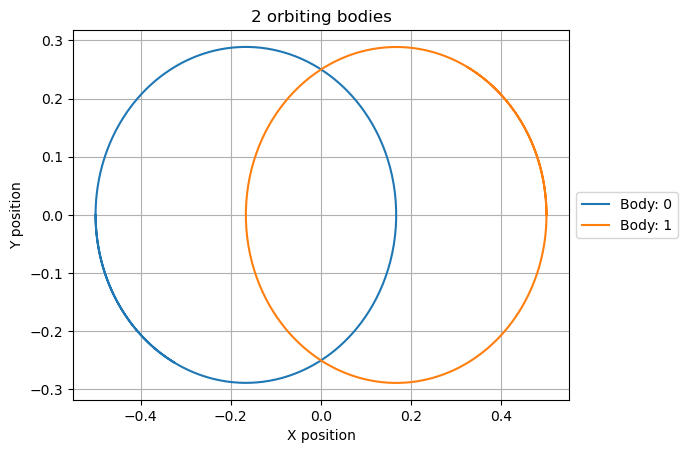

In [41]:
fig, ax = plt.subplots()

for j in range(len(m)):
    ax.plot(run[0][:,j,0], run[0][:,j,1], label = f"Body: {j}")

ax.set_title("2 orbiting bodies")
ax.set_xlabel("X position")
ax.set_ylabel("Y position")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid()

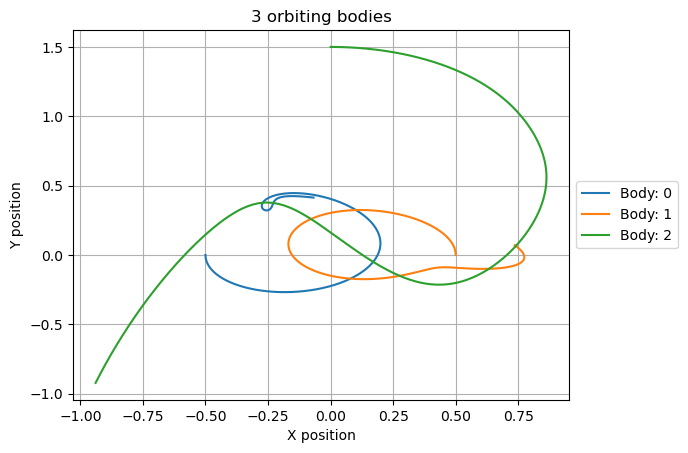

In [42]:
fig2, ax2 = plt.subplots()

for j in range(len(m2)):
    ax2.plot(run2[0][:,j,0], run2[0][:,j,1], label = f"Body: {j}")

ax2.set_title("3 orbiting bodies")
ax2.set_xlabel("X position")
ax2.set_ylabel("Y position")
ax2.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax2.grid()